In [2]:
# Importing Python Packages
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import numpy as np
import os

from sklearn.linear_model import Lasso

from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, KFold
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler, RobustScaler

from sklearn.metrics import explained_variance_score, mean_squared_log_error, median_absolute_error, max_error

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.utils.class_weight import compute_sample_weight


# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")


In [3]:
# Reading transaction dataset
dataset_path = r"H:\Documents\Bigdata_course\fraud_loan\transactions.csv"

tran_df = pd.read_csv(dataset_path ,sep=',')

# Displaying the dataset
tran_df.head()

,transaction_id,customer_id,transaction_date,transaction_type,transaction_amount,merchant_category,merchant_name,transaction_location,account_balance_after_transaction,is_international_transaction,device_used,ip_address,transaction_status,transaction_source_destination,transaction_notes,fraud_flag
0,2d7ddfd4-1112-4354-a2dd-fad94b45a850,CUST102188,2022-01-04 11:27:00,Bill Payment,2100.0,Dining,"Rattan, Khanna and Magar","Srikakulam, Himachal Pradesh",8211.0,0,Web,31.102.21.141,Success,BCHG80012468703731,Payment for Dining,0
1,ba998721-a612-4e0a-8354-46d001e9c39c,CUST107144,2022-01-03 23:52:00,UPI,1400.0,Travel,Chauhan LLC,"Giridih, Manipur",12858.0,0,Web,176.48.222.166,Success,CJPZ11841095072972,Payment for Travel,0
2,0b4ad8e2-40ac-49c9-b59a-c9efaaccc7a6,CUST102126,2022-01-15 06:54:00,Debit Card,1000.0,Entertainment,Halder-Sarma,"Avadi, Kerala",19268.0,0,ATM,181.62.105.161,Success,TLCG50761416960179,Payment for Entertainment,0
3,c4fce988-34c5-48db-8686-bfad0b3bc0b5,CUST109887,2022-01-08 07:57:00,Credit Card,10500.0,Utilities,"Anand, Khare and Balakrishnan","Navi Mumbai, Maharashtra",29585.0,0,ATM,121.157.246.80,Success,PRZJ55096553432036,Payment for Utilities,0
4,f9b8ca30-00e5-4322-8cff-eac0554cf2da,CUST108620,2022-01-02 10:43:00,Loan Disbursement,8100.0,Electronics,Zacharia and Sons,"Visakhapatnam, Gujarat",0.0,0,ATM,129.96.5.57,Success,NBAI29021393288369,Payment for Electronics,0


In [ ]:
# Reading loan application dataset
dataset_path = r"H:\Documents\Bigdata_course\fraud_loan\loan_applications.csv"

loan_df = pd.read_csv(dataset_path ,sep=',')

# Displaying the dataset
loan_df.head()

,application_id,customer_id,application_date,loan_type,loan_amount_requested,loan_tenure_months,interest_rate_offered,purpose_of_loan,employment_status,monthly_income,...,existing_emis_monthly,debt_to_income_ratio,property_ownership_status,residential_address,applicant_age,gender,number_of_dependents,loan_status,fraud_flag,fraud_type
0,c8bf0bea-70e6-4870-9125-41b8210c527f,CUST109427,2023-04-09,Business Loan,604000.0,12,11.66,Medical Emergency,Retired,34700.0,...,1100.0,3.17,Rented,"94/31, Sehgal Zila, Vadodara-380521, Anantapur...",28,Female,3,Approved,0,NaN
1,91224cec-3544-4bc7-ac15-a9792da54c02,CUST106146,2023-09-23,Car Loan,100000.0,240,13.62,Education,Unemployed,51600.0,...,0.0,0.00,Owned,"H.No. 00, Sheth Chowk, Ichalkaranji 006728, Im...",44,Other,3,Approved,0,NaN
2,4efcd02d-4a03-4ab7-9bd1-0ff430493d0c,CUST100674,2023-05-22,Education Loan,431000.0,60,11.40,Medical Emergency,Self-Employed,14800.0,...,4600.0,31.08,Rented,"H.No. 81, Dutta Path, Kozhikode-340301, Tadepa...",56,Other,4,Approved,0,NaN
3,a61337d4-ba04-4a68-b492-2cb8266e6ed7,CUST106466,2024-07-09,Car Loan,324000.0,120,10.36,Debt Consolidation,Self-Employed,28800.0,...,4000.0,13.89,Rented,"H.No. 022, Rege Road, Tiruvottiyur-927857, Aur...",27,Other,4,Declined,0,NaN
4,a8d1639e-170b-41b2-826a-55c7dae38d16,CUST112319,2023-11-20,Personal Loan,100000.0,36,14.14,Business Expansion,Salaried,43900.0,...,1100.0,2.51,Rented,"85/24, Bali Zila, Sambalpur 922071, Tumkur, Ke...",50,Other,0,Declined,0,NaN


In [5]:
#merging the datasets with columns of both the dataset present

merged_df = pd.merge(tran_df, loan_df, on='customer_id', how='outer')

#display the data

merged_df.head()

,transaction_id,customer_id,transaction_date,transaction_type,transaction_amount,merchant_category,merchant_name,transaction_location,account_balance_after_transaction,is_international_transaction,...,existing_emis_monthly,debt_to_income_ratio,property_ownership_status,residential_address,applicant_age,gender,number_of_dependents,loan_status,fraud_flag_y,fraud_type
0,ee57f580-a235-48b8-a562-bdfc09061af4,CUST100000,2022-01-20 15:33:00,Credit Card,2500.0,Electronics,"Viswanathan, Subramaniam and Kashyap","Howrah, Mizoram",0.0,0.0,...,2000.0,3.21,Jointly Owned,"321, Bassi Circle, Patna 133890, Bongaigaon, M...",61.0,Male,2.0,Approved,0.0,NaN
1,ee57f580-a235-48b8-a562-bdfc09061af4,CUST100000,2022-01-20 15:33:00,Credit Card,2500.0,Electronics,"Viswanathan, Subramaniam and Kashyap","Howrah, Mizoram",0.0,0.0,...,2000.0,3.21,Rented,"321, Bassi Circle, Patna 133890, Bongaigaon, M...",61.0,Male,2.0,Approved,0.0,NaN
2,ee57f580-a235-48b8-a562-bdfc09061af4,CUST100000,2022-01-20 15:33:00,Credit Card,2500.0,Electronics,"Viswanathan, Subramaniam and Kashyap","Howrah, Mizoram",0.0,0.0,...,2500.0,4.01,Rented,"321, Bassi Circle, Patna 133890, Bongaigaon, M...",61.0,Male,2.0,Approved,0.0,NaN
3,ee57f580-a235-48b8-a562-bdfc09061af4,CUST100000,2022-01-20 15:33:00,Credit Card,2500.0,Electronics,"Viswanathan, Subramaniam and Kashyap","Howrah, Mizoram",0.0,0.0,...,3500.0,5.61,Owned,"321, Bassi Circle, Patna 133890, Bongaigaon, M...",61.0,Male,2.0,Approved,0.0,NaN
4,ee57f580-a235-48b8-a562-bdfc09061af4,CUST100000,2022-01-20 15:33:00,Credit Card,2500.0,Electronics,"Viswanathan, Subramaniam and Kashyap","Howrah, Mizoram",0.0,0.0,...,1300.0,2.08,Owned,"321, Bassi Circle, Patna 133890, Bongaigaon, M...",61.0,Male,2.0,Approved,0.0,NaN


In [6]:
# Dataset inforamtion
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 133725 entries, 0 to 133724
Data columns (total 36 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   transaction_id                     129522 non-null  object 
 1   customer_id                        133725 non-null  object 
 2   transaction_date                   129522 non-null  object 
 3   transaction_type                   129522 non-null  object 
 4   transaction_amount                 129522 non-null  float64
 5   merchant_category                  129522 non-null  object 
 6   merchant_name                      129522 non-null  object 
 7   transaction_location               129522 non-null  object 
 8   account_balance_after_transaction  129522 non-null  float64
 9   is_international_transaction       129522 non-null  float64
 10  device_used                        129522 non-null  object 
 11  ip_address                         1295

In [7]:
# Count of columns
num_columns = len(merged_df.columns)

# Identify numerical int, float and categorical columns
numerical_int_columns = merged_df.select_dtypes(include=['int32', 'int64']).columns
numerical_float_columns = merged_df.select_dtypes(include=[ 'float32', 'float64']).columns
categorical_columns = merged_df.select_dtypes(include='object').columns
boolean_columns = merged_df.select_dtypes(include='bool').columns

# Display information
print(f"Total columns: {num_columns}")

if len(numerical_int_columns) > 0:
    print(f"\nNumerical integer columns ({len(numerical_int_columns)}): {', '.join(numerical_int_columns)}")
else:
    print(f"\nNo numerical integer columns found.")

if len(numerical_float_columns) > 0:
    print(f"\nNumerical float columns ({len(numerical_float_columns)}): {', '.join(numerical_float_columns)}")
else:
    print(f"\nNo numerical float columns found.")

if len(categorical_columns) > 0:
    print(f"\nCategorical columns ({len(categorical_columns)}): {', '.join(categorical_columns)}")
else:
    print(f"\nNo categorical columns found.")

if len(boolean_columns) > 0:
    print(f"\nBoolean columns ({len(boolean_columns)}): {', '.join(boolean_columns)}")
else:
    print(f"\nNo Boolean columns found.")

Total columns: 36

No numerical integer columns found.

Numerical float columns (14): transaction_amount, account_balance_after_transaction, is_international_transaction, fraud_flag_x, loan_amount_requested, loan_tenure_months, interest_rate_offered, monthly_income, cibil_score, existing_emis_monthly, debt_to_income_ratio, applicant_age, number_of_dependents, fraud_flag_y

Categorical columns (22): transaction_id, customer_id, transaction_date, transaction_type, merchant_category, merchant_name, transaction_location, device_used, ip_address, transaction_status, transaction_source_destination, transaction_notes, application_id, application_date, loan_type, purpose_of_loan, employment_status, property_ownership_status, residential_address, gender, loan_status, fraud_type

No Boolean columns found.


<h1 style="color:darkblue; font-weight:bold; font-size:40px;">
Data Preprocessing
</h1>



In [8]:
# Define a function to check for special characters


def has_special_chars(series, pattern=None):
    if pattern is None:
        # Default pattern includes common special characters
        pattern = r'[@_!#$%^&*()<>?/\|}{~:]'
    regex = re.compile(pattern)
    return series.astype(str).apply(lambda x: bool(regex.search(x))).any()

# Columns to exclude (e.g., date/time)
exclude_cols = ['transaction_date', 'application_date']

# Iterate and check each column
for col in merged_df.columns:
    if col.lower() not in exclude_cols:
        if has_special_chars(merged_df[col]):
            print(f" Special characters found in column: '{col}'")
        else:
            print(f" No special characters in column: '{col}'")

 No special characters in column: 'transaction_id'
 No special characters in column: 'customer_id'
 No special characters in column: 'transaction_type'
 No special characters in column: 'transaction_amount'
 No special characters in column: 'merchant_category'
 No special characters in column: 'merchant_name'
 Special characters found in column: 'transaction_location'
 No special characters in column: 'account_balance_after_transaction'
 No special characters in column: 'is_international_transaction'
 No special characters in column: 'device_used'
 No special characters in column: 'ip_address'
 No special characters in column: 'transaction_status'
 No special characters in column: 'transaction_source_destination'
 No special characters in column: 'transaction_notes'
 No special characters in column: 'fraud_flag_x'
 No special characters in column: 'application_id'
 No special characters in column: 'loan_type'
 No special characters in column: 'loan_amount_requested'
 No special charact

In [9]:
def get_special_char_rows(series, pattern=None):
    if pattern is None:
        pattern = r'[@_!#$%^&*()<>?/\|}{~:]'
    regex = re.compile(pattern)
    return series[series.astype(str).apply(lambda x: bool(regex.search(x)))]

# Example usage
for col in merged_df.columns:
    if col.lower() not in exclude_cols:
        flagged = get_special_char_rows(merged_df[col])
        if not flagged.empty:
            print(f"\n Values with special characters in '{col}':")
            print(flagged)



 Values with special characters in 'transaction_location':
467              Sangli-Miraj & Kupwad, Rajasthan
468              Sangli-Miraj & Kupwad, Rajasthan
469              Sangli-Miraj & Kupwad, Rajasthan
6126           Sangli-Miraj & Kupwad, Uttarakhand
6127           Sangli-Miraj & Kupwad, Uttarakhand
                           ...                   
131312    Sangli-Miraj & Kupwad, Himachal Pradesh
131313    Sangli-Miraj & Kupwad, Himachal Pradesh
131314    Sangli-Miraj & Kupwad, Himachal Pradesh
131315    Sangli-Miraj & Kupwad, Himachal Pradesh
132684         Sangli-Miraj & Kupwad, Maharashtra
Name: transaction_location, Length: 386, dtype: object

 Values with special characters in 'residential_address':
23        26/916, Raju Marg, Dehri 801845, Durg, Maharas...
24        26/916, Raju Marg, Dehri 801845, Durg, Maharas...
38        73/829, Khalsa, Bhalswa Jahangir Pur-311656, B...
39        73/829, Khalsa, Bhalswa Jahangir Pur-311656, B...
40        73/829, Khalsa, Bhalswa Ja

###### So there is no unnecessary character used

# Handle irrelevant columns
#### 1) Check for ID-like columns to drop

In [10]:

# Show the columns before and after identifying and dropping ID-like columns—those where every value is unique
# Step 1: Show all columns BEFORE dropping
print(" Columns BEFORE dropping ID-like columns:")
print(merged_df.columns.tolist())

# Step 2: Identify ID-like columns and excluding customer id
id_like_cols = [col for col in merged_df.columns if merged_df[col].nunique() == merged_df.shape[0] and col != 'customer_id']
print("\n ID-like columns to drop:")
print(id_like_cols)

 Columns BEFORE dropping ID-like columns:
['transaction_id', 'customer_id', 'transaction_date', 'transaction_type', 'transaction_amount', 'merchant_category', 'merchant_name', 'transaction_location', 'account_balance_after_transaction', 'is_international_transaction', 'device_used', 'ip_address', 'transaction_status', 'transaction_source_destination', 'transaction_notes', 'fraud_flag_x', 'application_id', 'application_date', 'loan_type', 'loan_amount_requested', 'loan_tenure_months', 'interest_rate_offered', 'purpose_of_loan', 'employment_status', 'monthly_income', 'cibil_score', 'existing_emis_monthly', 'debt_to_income_ratio', 'property_ownership_status', 'residential_address', 'applicant_age', 'gender', 'number_of_dependents', 'loan_status', 'fraud_flag_y', 'fraud_type']

 ID-like columns to drop:
[]


#### 2)Drop constant columns—those with only one unique value

In [11]:
# Step 1: Show columns BEFORE dropping
before_cols = set(merged_df.columns.tolist())
print(" Columns BEFORE dropping constant columns:")
print(list(before_cols))

# Step 2: Identify constant columns
constant_cols = [col for col in merged_df.columns if merged_df[col].nunique() == 1]
print("\n Constant columns to drop:")
print(constant_cols)


 Columns BEFORE dropping constant columns:
['transaction_amount', 'transaction_date', 'loan_status', 'transaction_type', 'employment_status', 'gender', 'fraud_flag_y', 'transaction_location', 'loan_type', 'transaction_id', 'merchant_name', 'interest_rate_offered', 'customer_id', 'applicant_age', 'transaction_notes', 'property_ownership_status', 'is_international_transaction', 'device_used', 'residential_address', 'number_of_dependents', 'fraud_type', 'debt_to_income_ratio', 'application_date', 'account_balance_after_transaction', 'transaction_status', 'monthly_income', 'transaction_source_destination', 'ip_address', 'fraud_flag_x', 'purpose_of_loan', 'existing_emis_monthly', 'loan_tenure_months', 'merchant_category', 'cibil_score', 'loan_amount_requested', 'application_id']

 Constant columns to drop:
[]


#### 3) Drop columns with more than 50% missing values

In [12]:


# Show columns before dropping
print("Columns BEFORE dropping:")
print(merged_df.columns.tolist())

# Identify columns with more than 50% missing values
missing_ratio = merged_df.isna().mean()
exclude_cols1 = ['fraud_flag_x', 'fraud_flag_y', 'fraud_type']
missing_values_cols = [col for col in missing_ratio[missing_ratio > 0.5].index if col not in exclude_cols1]

print("\n Columns with >50% missing values:")
print(missing_values_cols)


Columns BEFORE dropping:
['transaction_id', 'customer_id', 'transaction_date', 'transaction_type', 'transaction_amount', 'merchant_category', 'merchant_name', 'transaction_location', 'account_balance_after_transaction', 'is_international_transaction', 'device_used', 'ip_address', 'transaction_status', 'transaction_source_destination', 'transaction_notes', 'fraud_flag_x', 'application_id', 'application_date', 'loan_type', 'loan_amount_requested', 'loan_tenure_months', 'interest_rate_offered', 'purpose_of_loan', 'employment_status', 'monthly_income', 'cibil_score', 'existing_emis_monthly', 'debt_to_income_ratio', 'property_ownership_status', 'residential_address', 'applicant_age', 'gender', 'number_of_dependents', 'loan_status', 'fraud_flag_y', 'fraud_type']

 Columns with >50% missing values:
[]


#### 4) Dropping low-variance numeric features using VarianceThreshold

In [13]:


# Step 1: Select numeric columns
numeric_df = merged_df.select_dtypes(include=['int64', 'float64'])
print(" Numeric columns BEFORE filtering:")
print(numeric_df.columns.tolist())

# Step 2: Apply VarianceThreshold (but don't drop yet)
selector = VarianceThreshold(threshold=0.01)
selector.fit(numeric_df)

# Step 3: Identify low-variance columns
low_variance_cols = numeric_df.columns[~selector.get_support()]
print("\n Suggested low-variance columns to drop (variance ≤ 0.01):")
print(low_variance_cols)

 Numeric columns BEFORE filtering:
['transaction_amount', 'account_balance_after_transaction', 'is_international_transaction', 'fraud_flag_x', 'loan_amount_requested', 'loan_tenure_months', 'interest_rate_offered', 'monthly_income', 'cibil_score', 'existing_emis_monthly', 'debt_to_income_ratio', 'applicant_age', 'number_of_dependents', 'fraud_flag_y']

 Suggested low-variance columns to drop (variance ≤ 0.01):
Index(['is_international_transaction'], dtype='object')


#### 5) Drop categorical columns with high cardinality (i.e., too many unique values):

In [14]:

# Step 1: Identify categorical columns
cat_cols = merged_df.select_dtypes(include=['object', 'category']).columns

# Step 2: Show categorical columns BEFORE dropping
print(" Categorical columns BEFORE dropping high-cardinality features:")
print(cat_cols.tolist())

# Step 3: Identify high-cardinality columns (e.g., > 50 unique values)

exclude_cols2 = ['customer_id']
high_card_cols = [col for col in cat_cols if merged_df[col].nunique() > 50 and col not in exclude_cols2]
print("\n High-cardinality columns to drop:")
print(high_card_cols)

 Categorical columns BEFORE dropping high-cardinality features:
['transaction_id', 'customer_id', 'transaction_date', 'transaction_type', 'merchant_category', 'merchant_name', 'transaction_location', 'device_used', 'ip_address', 'transaction_status', 'transaction_source_destination', 'transaction_notes', 'application_id', 'application_date', 'loan_type', 'purpose_of_loan', 'employment_status', 'property_ownership_status', 'residential_address', 'gender', 'loan_status', 'fraud_type']

 High-cardinality columns to drop:
['transaction_id', 'transaction_date', 'merchant_name', 'transaction_location', 'ip_address', 'transaction_source_destination', 'application_id', 'application_date', 'residential_address']


#### 6) Check for high highly correlated features to drop to reduce multicollinearity

In [15]:

# Step 1: Show numeric columns BEFORE dropping
numeric_cols_before = merged_df.select_dtypes(include=['int64', 'float64']).columns.tolist()
print(" Numeric columns BEFORE dropping highly correlated ones:")
print(numeric_cols_before)

# Step 2: Compute correlation matrix and upper triangle
corr_matrix = merged_df.corr(numeric_only=True).abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Step 3: Identify highly correlated columns
high_corr_cols = [col for col in upper.columns if any(upper[col] > 0.95)]
print("\n Highly correlated columns to drop:")
print(high_corr_cols)

 Numeric columns BEFORE dropping highly correlated ones:
['transaction_amount', 'account_balance_after_transaction', 'is_international_transaction', 'fraud_flag_x', 'loan_amount_requested', 'loan_tenure_months', 'interest_rate_offered', 'monthly_income', 'cibil_score', 'existing_emis_monthly', 'debt_to_income_ratio', 'applicant_age', 'number_of_dependents', 'fraud_flag_y']

 Highly correlated columns to drop:
[]


In [16]:
# Ensure all components are lists (or empty lists if None)

# Ensure all are lists before concatenating
id_like_cols = id_like_cols if isinstance(id_like_cols, list) else list(id_like_cols)
constant_cols = constant_cols if isinstance(constant_cols, list) else list(constant_cols)
missing_values_cols = missing_values_cols if isinstance(missing_values_cols, list) else list(missing_values_cols)
low_variance_cols = list(low_variance_cols) if low_variance_cols is not None else []
high_card_cols = high_card_cols if isinstance(high_card_cols, list) else list(high_card_cols)
high_corr_cols = high_corr_cols if isinstance(high_corr_cols, list) else list(high_corr_cols)


# Now safely concatenate
irrelevant_cols = (
    id_like_cols +
    constant_cols +
    missing_values_cols +
    low_variance_cols +
    high_card_cols +
    high_corr_cols
)

print("\n Identified irrelevant columns to review:")
print(list(irrelevant_cols))



 Identified irrelevant columns to review:
['is_international_transaction', 'transaction_id', 'transaction_date', 'merchant_name', 'transaction_location', 'ip_address', 'transaction_source_destination', 'application_id', 'application_date', 'residential_address']


In [17]:
# Drop all or selected irrelevant columns
df_clean_cols = merged_df.drop(columns=irrelevant_cols)

# Print the modified DataFrame
print(df_clean_cols.head(5))

  customer_id transaction_type  transaction_amount merchant_category  \
0  CUST100000      Credit Card              2500.0       Electronics   
1  CUST100000      Credit Card              2500.0       Electronics   
2  CUST100000      Credit Card              2500.0       Electronics   
3  CUST100000      Credit Card              2500.0       Electronics   
4  CUST100000      Credit Card              2500.0       Electronics   

   account_balance_after_transaction device_used transaction_status  \
0                                0.0         POS            Success   
1                                0.0         POS            Success   
2                                0.0         POS            Success   
3                                0.0         POS            Success   
4                                0.0         POS            Success   

         transaction_notes  fraud_flag_x       loan_type  ...  cibil_score  \
0  Payment for Electronics           0.0        Car Loan  ... 

In [18]:
# Manually drop other irrelevant columns if required only

print(" Columns BEFORE dropping irrelevant ones:")
print(df_clean_cols.columns.tolist())

# Step 2: Define and drop irrelevant columns
other_irrelevant_cols = ['fraud_type']
df_clean_cols.drop(columns=[col for col in other_irrelevant_cols if col in df_clean_cols.columns], inplace=True)

# Step 3: Show columns AFTER dropping
print("\n Columns AFTER dropping irrelevant ones:")
print(df_clean_cols.columns.tolist())

 Columns BEFORE dropping irrelevant ones:
['customer_id', 'transaction_type', 'transaction_amount', 'merchant_category', 'account_balance_after_transaction', 'device_used', 'transaction_status', 'transaction_notes', 'fraud_flag_x', 'loan_type', 'loan_amount_requested', 'loan_tenure_months', 'interest_rate_offered', 'purpose_of_loan', 'employment_status', 'monthly_income', 'cibil_score', 'existing_emis_monthly', 'debt_to_income_ratio', 'property_ownership_status', 'applicant_age', 'gender', 'number_of_dependents', 'loan_status', 'fraud_flag_y', 'fraud_type']

 Columns AFTER dropping irrelevant ones:
['customer_id', 'transaction_type', 'transaction_amount', 'merchant_category', 'account_balance_after_transaction', 'device_used', 'transaction_status', 'transaction_notes', 'fraud_flag_x', 'loan_type', 'loan_amount_requested', 'loan_tenure_months', 'interest_rate_offered', 'purpose_of_loan', 'employment_status', 'monthly_income', 'cibil_score', 'existing_emis_monthly', 'debt_to_income_ratio

### Handling duplicate rows

In [19]:
# Step 1: Show DataFrame BEFORE dropping duplicates
print(" DataFrame BEFORE dropping duplicates:")
print(f"Total rows: {df_clean_cols.shape[0]}")
print(df_clean_cols.head())  # Preview top rows

# Step 2: Count duplicated rows
num_duplicates = df_clean_cols.duplicated().sum()
print(f"\n Number of duplicated rows: {num_duplicates}")

# Step 3: Optionally, show the duplicated rows
print("\n Duplicated rows preview:")
print(df_clean_cols[df_clean_cols.duplicated()].head())  # Show first few duplicate rows


 DataFrame BEFORE dropping duplicates:
Total rows: 133725
  customer_id transaction_type  transaction_amount merchant_category  \
0  CUST100000      Credit Card              2500.0       Electronics   
1  CUST100000      Credit Card              2500.0       Electronics   
2  CUST100000      Credit Card              2500.0       Electronics   
3  CUST100000      Credit Card              2500.0       Electronics   
4  CUST100000      Credit Card              2500.0       Electronics   

   account_balance_after_transaction device_used transaction_status  \
0                                0.0         POS            Success   
1                                0.0         POS            Success   
2                                0.0         POS            Success   
3                                0.0         POS            Success   
4                                0.0         POS            Success   

         transaction_notes  fraud_flag_x       loan_type  ...  monthly_income  \
0

### Handle Outliers with IQR Method

In [20]:
#Showing DataFrame BEFORE handling outliers
print(" DataFrame BEFORE handling outliers:")
print(f"Rows: {df_clean_cols.shape[0]}, Columns: {df_clean_cols.shape[1]}")
print(df_clean_cols.describe())

# Applying IQR method only to numeric columns

numeric_cols = df_clean_cols.select_dtypes(include='number').columns
numeric_cols = [col for col in numeric_cols if col not in ['fraud_flag_x', 'fraud_flag_y']]
Q1 = df_clean_cols[numeric_cols].quantile(0.25)
Q3 = df_clean_cols[numeric_cols].quantile(0.75)
IQR = Q3 - Q1

# Any value below the lower bound or above the upper bound is considered an extreme outlier.
# Filtering rows within IQR bounds
condition = ~((df_clean_cols[numeric_cols] < (Q1 - 3 * IQR)) | (df_clean_cols[numeric_cols] > (Q3 + 3 * IQR))).any(axis=1)
df_clean_cols_rows = df_clean_cols[condition]

#  Showing DataFrame AFTER handling outliers
print("\n DataFrame AFTER handling outliers:")
print(f"Rows: {df_clean_cols_rows.shape[0]}, Columns: {df_clean_cols_rows.shape[1]}")
print(df_clean_cols_rows.describe())

#Showing how many rows were removed
removed_rows = df_clean_cols.shape[0] - df_clean_cols_rows.shape[0]
print(f"\n Outlier rows removed: {removed_rows}")

 DataFrame BEFORE handling outliers:
Rows: 133725, Columns: 25
       transaction_amount  account_balance_after_transaction   fraud_flag_x  \
count       129522.000000                      129522.000000  129522.000000   
mean          4985.180421                       21902.939354       0.010199   
std           5058.433509                       14632.170410       0.100474   
min            100.000000                           0.000000       0.000000   
25%           1400.000000                        9209.000000       0.000000   
50%           3400.000000                       21506.500000       0.000000   
75%           6900.000000                       33958.000000       0.000000   
max          76531.610223                       89097.000000       1.000000   

       loan_amount_requested  loan_tenure_months  interest_rate_offered  \
count           1.294840e+05       129484.000000          129484.000000   
mean            5.143832e+05          121.455655              10.527164   


In [21]:

print(f"Original rows: {df_clean_cols.shape[0]}")
print(f"After filtering: {df_clean_cols_rows.shape[0]}")
print(f"Rows removed: {df_clean_cols.shape[0] - df_clean_cols_rows.shape[0]}")


Original rows: 133725
After filtering: 127872
Rows removed: 5853


In [22]:
df_clean_cols_rows.head(2)

,customer_id,transaction_type,transaction_amount,merchant_category,account_balance_after_transaction,device_used,transaction_status,transaction_notes,fraud_flag_x,loan_type,...,monthly_income,cibil_score,existing_emis_monthly,debt_to_income_ratio,property_ownership_status,applicant_age,gender,number_of_dependents,loan_status,fraud_flag_y
0,CUST100000,Credit Card,2500.0,Electronics,0.0,POS,Success,Payment for Electronics,0.0,Car Loan,...,62400.0,690.0,2000.0,3.21,Jointly Owned,61.0,Male,2.0,Approved,0.0
1,CUST100000,Credit Card,2500.0,Electronics,0.0,POS,Success,Payment for Electronics,0.0,Business Loan,...,62400.0,704.0,2000.0,3.21,Rented,61.0,Male,2.0,Approved,0.0


<h3 style="color:darkblue; font-weight:bold;">
Aggregating Columns
</h3>

In [23]:
#assigning simple name
df = df_clean_cols_rows

In [24]:
#making single column for fraud

df['fraud_flag'] = ((df['fraud_flag_x'] == 1.0) | (df['fraud_flag_y'] == 1.0)).astype(int)
#this will merge trans fraud and loan fraud and give boolean true if any one true


In [25]:
#droping after merging
df = df.drop(['fraud_flag_x', 'fraud_flag_y'], axis=1)

In [26]:
#Aggregating numeric comumn 

import pandas as pd

# Example: numeric columns in your DataFrame
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Define which stats make sense per column type
# Columns where 'sum' is meaningful
sum_cols = [
    'transaction_amount', 
    'loan_amount_requested', 
    'existing_emis_monthly', 
    'fraud_flag'
]

# Columns where 'sum' does NOT make sense
mean_max_cols = [col for col in num_cols if col not in sum_cols]

# Create a dictionary for aggregation
agg_dict = {}

# Add mean and max for all numeric columns
for col in mean_max_cols:
    agg_dict[col] = ['mean', 'max']

# Add mean, max, sum for columns where sum makes sense
for col in sum_cols:
    agg_dict[col] = ['mean', 'max', 'sum']

# Perform aggregation
num_agg = df.groupby('customer_id').agg(agg_dict)

# Flatten multi-level column names
num_agg.columns = ['_'.join(col) for col in num_agg.columns]


num_agg.head()


,account_balance_after_transaction_mean,account_balance_after_transaction_max,loan_tenure_months_mean,loan_tenure_months_max,interest_rate_offered_mean,interest_rate_offered_max,monthly_income_mean,monthly_income_max,cibil_score_mean,cibil_score_max,...,transaction_amount_sum,loan_amount_requested_mean,loan_amount_requested_max,loan_amount_requested_sum,existing_emis_monthly_mean,existing_emis_monthly_max,existing_emis_monthly_sum,fraud_flag_mean,fraud_flag_max,fraud_flag_sum
customer_id,,,,,,,,,,,,,,,,,,,,,
CUST100000,8708.000000,17416.0,112.8,240.0,11.032000,13.04,62400.0,62400.0,721.000000,795.0,...,13500.0,474800.0,625000.0,4748000.0,2260.000000,3500.0,22600.0,0.0,0,0
CUST100001,18163.666667,24469.0,60.0,60.0,9.600000,9.60,46500.0,46500.0,628.000000,628.0,...,23200.0,396000.0,396000.0,1188000.0,6000.000000,6000.0,18000.0,0.0,0,0
CUST100002,NaN,NaN,120.0,120.0,12.650000,12.65,66200.0,66200.0,724.000000,724.0,...,0.0,673000.0,673000.0,673000.0,3400.000000,3400.0,3400.0,0.0,0,0
CUST100003,18887.000000,32300.0,280.0,360.0,12.036667,14.73,88100.0,88100.0,703.333333,743.0,...,39600.0,392000.0,793000.0,3528000.0,3833.333333,6900.0,34500.0,0.0,0,0
CUST100004,NaN,NaN,24.0,36.0,9.565000,10.16,44100.0,44100.0,721.500000,799.0,...,0.0,602000.0,705000.0,1204000.0,3750.000000,6000.0,7500.0,0.0,0,0


In [27]:
#Get number of unique values per category
# Select categorical columns
cat_cols = df.select_dtypes(include=['object', 'category']).columns

# Exclude customer_id
cat_cols = [col for col in cat_cols if col != 'customer_id']

# Aggregate categorical columns per customer
cat_agg = df.groupby('customer_id')[cat_cols].agg(['nunique'])

# Flatten multi-level column names if needed
cat_agg.columns = ['_'.join(col) for col in cat_agg.columns]

In [28]:
#2. Get most frequent (mode) value per customer

cat_mode = df.groupby('customer_id')[cat_cols].agg(
    lambda x: x.mode()[0] if not x.mode().empty else np.nan
)

cat_mode.columns = [f"{col}_mode" if col != 'customer_id' else col for col in cat_mode.columns]

In [29]:
cat_mode.head()

,transaction_type_mode,merchant_category_mode,device_used_mode,transaction_status_mode,transaction_notes_mode,loan_type_mode,purpose_of_loan_mode,employment_status_mode,property_ownership_status_mode,gender_mode,loan_status_mode
customer_id,,,,,,,,,,,
CUST100000,Credit Card,Electronics,Mobile,Success,Payment for Electronics,Business Loan,Vehicle Purchase,Salaried,Owned,Male,Approved
CUST100001,Debit Card,Cash Withdrawal,ATM,Success,Payment for Cash Withdrawal,Business Loan,Wedding,Self-Employed,Jointly Owned,Male,Declined
CUST100002,NaN,NaN,NaN,NaN,NaN,Car Loan,Medical Emergency,Student,Jointly Owned,Other,Approved
CUST100003,Credit Card,Fuel,POS,Success,Payment for Fuel,Car Loan,Business Expansion,Salaried,Owned,Female,Approved
CUST100004,NaN,NaN,NaN,NaN,NaN,Car Loan,Home Renovation,Self-Employed,Owned,Male,Approved


In [30]:
#combining unique and mode
#Combine both (optional)
cat_features = cat_agg.merge(cat_mode, on='customer_id', suffixes=('_nunique', '_mode')) #surffixes work only if the columns names are same


In [31]:
cat_features.head()

,transaction_type_nunique,merchant_category_nunique,device_used_nunique,transaction_status_nunique,transaction_notes_nunique,loan_type_nunique,purpose_of_loan_nunique,employment_status_nunique,property_ownership_status_nunique,gender_nunique,...,merchant_category_mode,device_used_mode,transaction_status_mode,transaction_notes_mode,loan_type_mode,purpose_of_loan_mode,employment_status_mode,property_ownership_status_mode,gender_mode,loan_status_mode
customer_id,,,,,,,,,,,,,,,,,,,,,
CUST100000,1,2,2,1,2,4,4,1,3,1,...,Electronics,Mobile,Success,Payment for Electronics,Business Loan,Vehicle Purchase,Salaried,Owned,Male,Approved
CUST100001,3,3,3,1,3,1,1,1,1,1,...,Cash Withdrawal,ATM,Success,Payment for Cash Withdrawal,Business Loan,Wedding,Self-Employed,Jointly Owned,Male,Declined
CUST100002,0,0,0,0,0,1,1,1,1,1,...,NaN,NaN,NaN,NaN,Car Loan,Medical Emergency,Student,Jointly Owned,Other,Approved
CUST100003,3,3,2,1,3,2,3,1,2,1,...,Fuel,POS,Success,Payment for Fuel,Car Loan,Business Expansion,Salaried,Owned,Female,Approved
CUST100004,0,0,0,0,0,2,2,1,2,1,...,NaN,NaN,NaN,NaN,Car Loan,Home Renovation,Self-Employed,Owned,Male,Approved


In [32]:
# Combining numerical and categorical dataframe

#Make sure both have customer_id as the index or column
num_agg = num_agg.reset_index()
cat_features = cat_features.reset_index()

#Merge the two DataFrames
customer_df = num_agg.merge(cat_features, on='customer_id', how='inner')
#how='inner' - keeps only customers present in both DataFrames

#seting customer_id as index again
#customer_df = customer_df.set_index('customer_id')



In [33]:
customer_df.head(5)

,customer_id,account_balance_after_transaction_mean,account_balance_after_transaction_max,loan_tenure_months_mean,loan_tenure_months_max,interest_rate_offered_mean,interest_rate_offered_max,monthly_income_mean,monthly_income_max,cibil_score_mean,...,merchant_category_mode,device_used_mode,transaction_status_mode,transaction_notes_mode,loan_type_mode,purpose_of_loan_mode,employment_status_mode,property_ownership_status_mode,gender_mode,loan_status_mode
0,CUST100000,8708.000000,17416.0,112.8,240.0,11.032000,13.04,62400.0,62400.0,721.000000,...,Electronics,Mobile,Success,Payment for Electronics,Business Loan,Vehicle Purchase,Salaried,Owned,Male,Approved
1,CUST100001,18163.666667,24469.0,60.0,60.0,9.600000,9.60,46500.0,46500.0,628.000000,...,Cash Withdrawal,ATM,Success,Payment for Cash Withdrawal,Business Loan,Wedding,Self-Employed,Jointly Owned,Male,Declined
2,CUST100002,NaN,NaN,120.0,120.0,12.650000,12.65,66200.0,66200.0,724.000000,...,NaN,NaN,NaN,NaN,Car Loan,Medical Emergency,Student,Jointly Owned,Other,Approved
3,CUST100003,18887.000000,32300.0,280.0,360.0,12.036667,14.73,88100.0,88100.0,703.333333,...,Fuel,POS,Success,Payment for Fuel,Car Loan,Business Expansion,Salaried,Owned,Female,Approved
4,CUST100004,NaN,NaN,24.0,36.0,9.565000,10.16,44100.0,44100.0,721.500000,...,NaN,NaN,NaN,NaN,Car Loan,Home Renovation,Self-Employed,Owned,Male,Approved


In [34]:
customer_df.columns

Index(['customer_id', 'account_balance_after_transaction_mean',
       'account_balance_after_transaction_max', 'loan_tenure_months_mean',
       'loan_tenure_months_max', 'interest_rate_offered_mean',
       'interest_rate_offered_max', 'monthly_income_mean',
       'monthly_income_max', 'cibil_score_mean', 'cibil_score_max',
       'debt_to_income_ratio_mean', 'debt_to_income_ratio_max',
       'applicant_age_mean', 'applicant_age_max', 'number_of_dependents_mean',
       'number_of_dependents_max', 'transaction_amount_mean',
       'transaction_amount_max', 'transaction_amount_sum',
       'loan_amount_requested_mean', 'loan_amount_requested_max',
       'loan_amount_requested_sum', 'existing_emis_monthly_mean',
       'existing_emis_monthly_max', 'existing_emis_monthly_sum',
       'fraud_flag_mean', 'fraud_flag_max', 'fraud_flag_sum',
       'transaction_type_nunique', 'merchant_category_nunique',
       'device_used_nunique', 'transaction_status_nunique',
       'transaction_note

In [35]:
# Feature Engineering

customer_df['avg_tran_amount_per_income'] = customer_df['transaction_amount_mean'] / (customer_df['monthly_income_mean'] + 1) 

 
customer_df['max_to_mean_balance_ratio'] = customer_df['account_balance_after_transaction_max'] / (customer_df['account_balance_after_transaction_mean'] + 1) 

 
customer_df['loan_to_income_ratio'] = customer_df['loan_amount_requested_mean'] / (customer_df['monthly_income_mean'] + 1)





In [36]:
customer_df['is_fraud_customer'] = (customer_df['fraud_flag_sum'] > 0).astype(int)

In [37]:
fraud_rows = customer_df[customer_df['fraud_flag_sum'] >= 1]
fraud_rows.head(2)


,customer_id,account_balance_after_transaction_mean,account_balance_after_transaction_max,loan_tenure_months_mean,loan_tenure_months_max,interest_rate_offered_mean,interest_rate_offered_max,monthly_income_mean,monthly_income_max,cibil_score_mean,...,loan_type_mode,purpose_of_loan_mode,employment_status_mode,property_ownership_status_mode,gender_mode,loan_status_mode,avg_tran_amount_per_income,max_to_mean_balance_ratio,loan_to_income_ratio,is_fraud_customer
29,CUST100032,28537.718,43934.0,128.0,360.0,11.286667,11.74,49700.0,49700.0,701.00,...,Car Loan,Wedding,Student,Owned,Male,Fraudulent - Undetected,0.064129,1.539452,8.873061,1
43,CUST100047,NaN,NaN,189.0,360.0,12.442500,12.54,76400.0,76400.0,714.75,...,Education Loan,Business Expansion,Student,Rented,Male,Fraudulent - Detected,NaN,NaN,4.610542,1


In [38]:
list(customer_df.columns)

['customer_id',
 'account_balance_after_transaction_mean',
 'account_balance_after_transaction_max',
 'loan_tenure_months_mean',
 'loan_tenure_months_max',
 'interest_rate_offered_mean',
 'interest_rate_offered_max',
 'monthly_income_mean',
 'monthly_income_max',
 'cibil_score_mean',
 'cibil_score_max',
 'debt_to_income_ratio_mean',
 'debt_to_income_ratio_max',
 'applicant_age_mean',
 'applicant_age_max',
 'number_of_dependents_mean',
 'number_of_dependents_max',
 'transaction_amount_mean',
 'transaction_amount_max',
 'transaction_amount_sum',
 'loan_amount_requested_mean',
 'loan_amount_requested_max',
 'loan_amount_requested_sum',
 'existing_emis_monthly_mean',
 'existing_emis_monthly_max',
 'existing_emis_monthly_sum',
 'fraud_flag_mean',
 'fraud_flag_max',
 'fraud_flag_sum',
 'transaction_type_nunique',
 'merchant_category_nunique',
 'device_used_nunique',
 'transaction_status_nunique',
 'transaction_notes_nunique',
 'loan_type_nunique',
 'purpose_of_loan_nunique',
 'employment_sta

### Build a Fraud Risk Model (Customer-Level Classification) 

##### Handle Missing Values (Numerical + Categorical)

In [39]:
from sklearn.impute import SimpleImputer

def dynamic_imputer(df, fitted_imputers=None, fit=True):
    """
    Dynamically imputes missing values column by column.

    If fit=True, fits new imputers on df and returns both df_imputed and the fitted imputers.
    If fit=False, applies previously fitted imputers to df.
    """
    df_imputed = df.copy()
    imputers = {} if fit else fitted_imputers

    for col in df.columns:
        if df[col].isnull().sum() == 0:
            continue  # no missing values

        if fit:
            # Choose strategy dynamically
            if df[col].dtype == 'object' or df[col].dtype.name == 'category':
                strategy = 'most_frequent'
            elif 'datetime' in str(df[col].dtype):
                #print(f" Column: {col} → Datetime, skipping imputation")
                continue
            else:
                skew = df[col].dropna().skew()
                strategy = 'mean' if abs(skew) < 1 else 'median'

            #print(f" Column: {col} → Strategy: {strategy}")
            imputer = SimpleImputer(strategy=strategy)
            df_imputed[[col]] = imputer.fit_transform(df[[col]])
            imputers[col] = imputer

        else:
            # Apply already fitted imputer
            if col in imputers:
                df_imputed[[col]] = imputers[col].transform(df[[col]])

    return df_imputed, imputers


In [40]:

def run_classification(df_clean, target_column=None, model_name=None, label_encode_cols=None, onehot_encode_cols=None, scale_cols=None, scaler=None, num_rows=None):

    # Copy the original DataFrame to avoid modifying it
    df_copy = df_clean.copy()

    # FEATURE ENGINEERING
    if num_rows is not None:
        df_copy = df_copy.sample(n=num_rows, random_state=42)
    
    # Separate features (X) and target variable (y)
    X = df_copy.drop(columns=[target_column, 'fraud_flag_mean', 'fraud_flag_max', 'fraud_flag_sum'], axis=1, errors='ignore')
    y = df_copy[target_column]

    # SPLITTING DATA
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


     # Impute missing values dynamically 
    X_train_imputed, imputers = dynamic_imputer(X_train, fit=True)
    X_test_imputed, _ = dynamic_imputer(X_test, fitted_imputers=imputers, fit=False)
    
    # Use these going forward
    X_train = X_train_imputed
    X_test = X_test_imputed


    
    # LABEL ENCODING
    if label_encode_cols:
        for col in label_encode_cols:
            le = LabelEncoder()
            X_train[col] = le.fit_transform(X_train[col].astype(str))
            # handle unseen categories in test set
            X_test[col] = X_test[col].astype(str).map(lambda s: le.transform([s])[0] if s in le.classes_ else -1)

    # ONE-HOT ENCODING
    if onehot_encode_cols:
        X_train = pd.get_dummies(X_train, columns=onehot_encode_cols, drop_first=True)
        X_test = pd.get_dummies(X_test, columns=onehot_encode_cols, drop_first=True)

        # align columns between train and test
        X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

    
    # SCALING
    if scale_cols and scaler:
        if scaler == 'standard':
            scaler_instance = StandardScaler()
        elif scaler == 'minmax':
            scaler_instance = MinMaxScaler()
        elif scaler == 'robust':
            scaler_instance = RobustScaler()
        else:
            raise ValueError("Invalid scaler. Choose from 'standard', 'minmax', 'robust'.")
        
        X_train[scale_cols] = scaler_instance.fit_transform(X_train[scale_cols])
        X_test[scale_cols] = scaler_instance.transform(X_test[scale_cols])

    # MODELLING
    # Initialize the selected model
    
    if model_name == 'LR':
        model_type = 'Logistic Regression'
        model = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
    
    elif model_name == 'DT':
        model_type = 'Decision Tree Classifier'
        model = DecisionTreeClassifier(random_state=42, class_weight='balanced')
        
    elif model_name == 'RF':
        model_type = 'Random Forest Classifier'
        model = RandomForestClassifier(random_state=42, class_weight='balanced')
        
    elif model_name == 'GB':
        model_type = 'Gradient Boosting Classifier'
        model = GradientBoostingClassifier(random_state=42)
        
    elif model_name == 'SVM':
        model_type = 'Support Vector Machine'
        model = SVC(probability=True, random_state=42, class_weight='balanced')
        
    elif model_name == 'NB':
        model_type = 'Naive Bayes Classifier'
        model = GaussianNB()
        
    else:
        raise ValueError("Invalid model_name. Choose 'LR' for Linear Regression, 'DT' for Decision Tree Regression, or 'RF' for Random Forest Regression,'GB' for Gradient Boosting Classifier, 'SVM' for Support Vector Machine, 'NB' for Naive Bayes Classifier")

  
    # Fit the model
    model.fit(X_train, y_train)

    # Make predictions
    y_pred = model.predict(X_test)

    

    # Evaluate the model

    accuracy  = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall    = recall_score(y_test, y_pred)
    f1        = f1_score(y_test, y_pred)
    if hasattr(model, "predict_proba"):
        roc_auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]) 
    else:
        roc_auc = None
        
    # Display the evaluation metrics
    print(f"\n{model_type} Accuracy:", accuracy)
    print(f"{model_type} Precision:", precision)
    print(f"{model_type} Recall:", recall)
    print(f"{model_type} F1-score:", f1)
    if roc_auc is not None:
        print(f"{model_type} ROC-AUC:", roc_auc)

    # Store metrics in a dictionary
    metrics = {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-score': f1,
        'ROC-AUC': roc_auc
    }
    return metrics
    

#Accuracy: Proportion of correctly predicted observations out of all observations.
#Precision: Proportion of correctly predicted positive observations out of all predicted positives.
#Recall (Sensitivity / True Positive Rate): Proportion of correctly predicted positive observations out of all actual positives.
#F1-score: Harmonic mean of Precision and Recall. Balances the trade-off between precision and recall.



### Analyse columns to normalize and encode

In [41]:
def analyze_encoding_strategy(af, target=None):
    normalize_cols = []
    label_encode_cols = []
    one_hot_encode_cols = []

    for col in af.columns:
        if col == target:
            continue  # Skip target column

        dtype = af[col].dtype
        unique_vals = af[col].nunique()

        # Skip ID-like columns
        if unique_vals == af.shape[0]:
            continue

        # Numeric columns
        if pd.api.types.is_numeric_dtype(dtype):
            if unique_vals > 50:
                normalize_cols.append(col)
        else:
            # Categorical columns
            if unique_vals == 2:
                label_encode_cols.append(col)
            elif unique_vals <= 10:
                one_hot_encode_cols.append(col)
            else:
                print(f" High-cardinality column: {col} ({unique_vals} unique values)")

    return normalize_cols, label_encode_cols, one_hot_encode_cols

# Example usage
target_col = 'is_fraud_customer'
norm_cols, label_cols, onehot_cols = analyze_encoding_strategy(customer_df, target=target_col)

print(" Normalize:", norm_cols)
print(" Label Encode:", label_cols)
print(" One-Hot Encode:", onehot_cols)


 High-cardinality column: merchant_category_mode (12 unique values)
 High-cardinality column: transaction_notes_mode (12 unique values)
 Normalize: ['account_balance_after_transaction_mean', 'account_balance_after_transaction_max', 'loan_tenure_months_mean', 'interest_rate_offered_mean', 'interest_rate_offered_max', 'monthly_income_mean', 'monthly_income_max', 'cibil_score_mean', 'cibil_score_max', 'debt_to_income_ratio_mean', 'debt_to_income_ratio_max', 'transaction_amount_mean', 'transaction_amount_max', 'transaction_amount_sum', 'loan_amount_requested_mean', 'loan_amount_requested_max', 'loan_amount_requested_sum', 'existing_emis_monthly_mean', 'existing_emis_monthly_max', 'existing_emis_monthly_sum', 'avg_tran_amount_per_income', 'max_to_mean_balance_ratio', 'loan_to_income_ratio']
 Label Encode: ['transaction_status_mode']
 One-Hot Encode: ['transaction_type_mode', 'device_used_mode', 'loan_type_mode', 'purpose_of_loan_mode', 'employment_status_mode', 'property_ownership_status_mo

In [42]:
#dropping high cardinality

# Drop the high-cardinality columns
customer_df = customer_df.drop(columns=['merchant_category_mode', 'transaction_notes_mode', 'customer_id'])
customer_df.head(2)


,account_balance_after_transaction_mean,account_balance_after_transaction_max,loan_tenure_months_mean,loan_tenure_months_max,interest_rate_offered_mean,interest_rate_offered_max,monthly_income_mean,monthly_income_max,cibil_score_mean,cibil_score_max,...,loan_type_mode,purpose_of_loan_mode,employment_status_mode,property_ownership_status_mode,gender_mode,loan_status_mode,avg_tran_amount_per_income,max_to_mean_balance_ratio,loan_to_income_ratio,is_fraud_customer
0,8708.000000,17416.0,112.8,240.0,11.032,13.04,62400.0,62400.0,721.0,795.0,...,Business Loan,Vehicle Purchase,Salaried,Owned,Male,Approved,0.021634,1.999770,7.608852,0
1,18163.666667,24469.0,60.0,60.0,9.600,9.60,46500.0,46500.0,628.0,628.0,...,Business Loan,Wedding,Self-Employed,Jointly Owned,Male,Declined,0.166305,1.347066,8.515946,0


In [43]:
# Specify all paramters: the columns for label encoding, one-hot encoding, and scaling
label_encode_cols = label_cols
onehot_encode_cols = onehot_cols

# Specify numerical columns columns for scaling 
scale_cols =  norm_cols

# Specify the target column name
target_column_name = 'is_fraud_customer'

# Specify the number of rows for the model
num_rows = customer_df.shape[0]

In [44]:
# Choose right scaler dynamically depends on the distribution of your data

def suggest_scaler(bf, numeric_agg):
    skewness_scores = []
    outlier_ratios = []

    for col in numeric_agg:
        series = bf[col].dropna()
        skewness = series.skew()
        iqr = series.quantile(0.75) - series.quantile(0.25)
        outliers = np.sum(np.abs(series - series.median()) > 1.5 * iqr) / len(series)

        skewness_scores.append(abs(skewness))
        outlier_ratios.append(outliers)

    avg_skew = np.mean(skewness_scores)
    avg_outliers = np.mean(outlier_ratios)

    print(f" Avg Skewness: {avg_skew:.2f}")
    print(f" Avg Outlier Ratio: {avg_outliers:.2f}")

    if avg_outliers > 0.15:
        return "robust"
    elif avg_skew > 1:
        return "minmax"
    else:
        return "standard"

num_agg = [col for col in num_agg if col != 'customer_id']
scaler_name = suggest_scaler(customer_df, num_agg)
print(f" Suggested Scaler for all features: {scaler_name}")

# RobustScaler → If outliers dominate
# MinMaxScaler → If data is skewed but not extreme
# StandardScaler → If data is roughly Gaussian and clean

 Avg Skewness: 1.66
 Avg Outlier Ratio: 0.05
 Suggested Scaler for all features: minmax


In [45]:

# Run Logistic Regression and print metrics
lr_metrics = run_classification(customer_df, target_column=target_column_name, model_name='LR', label_encode_cols=label_encode_cols,
                                onehot_encode_cols=onehot_encode_cols, scale_cols=scale_cols, scaler=scaler_name)



Logistic Regression Accuracy: 0.9974470257850395
Logistic Regression Precision: 0.9
Logistic Regression Recall: 0.972972972972973
Logistic Regression F1-score: 0.935064935064935
Logistic Regression ROC-AUC: 0.9970778741270545


In [46]:
# Run Decision Tree Classifier
dt_metrics = run_classification(customer_df, target_column=target_column_name, model_name='DT', label_encode_cols=label_encode_cols,onehot_encode_cols=onehot_encode_cols, 
    scale_cols=scale_cols, scaler=scaler_name)



Decision Tree Classifier Accuracy: 0.9989788103140158
Decision Tree Classifier Precision: 0.9861111111111112
Decision Tree Classifier Recall: 0.9594594594594594
Decision Tree Classifier F1-score: 0.9726027397260274
Decision Tree Classifier ROC-AUC: 0.9795996230422459


In [47]:
# Run Random Forest Classifier
rf_metrics = run_classification(df_clean=customer_df, target_column=target_column_name, model_name='RF', label_encode_cols=label_encode_cols,
    onehot_encode_cols=onehot_encode_cols, scale_cols=scale_cols, scaler=scaler_name)


Random Forest Classifier Accuracy: 0.9992341077355119
Random Forest Classifier Precision: 1.0
Random Forest Classifier Recall: 0.9594594594594594
Random Forest Classifier F1-score: 0.9793103448275862
Random Forest Classifier ROC-AUC: 0.9894332271381452


In [48]:
# Run Gradient Boosting Classifier
gb_metrics = run_classification(df_clean=customer_df, target_column=target_column_name, model_name='GB', label_encode_cols=label_encode_cols,
    onehot_encode_cols=onehot_encode_cols, scale_cols=scale_cols, scaler=scaler_name)


Gradient Boosting Classifier Accuracy: 0.9994894051570079
Gradient Boosting Classifier Precision: 1.0
Gradient Boosting Classifier Recall: 0.972972972972973
Gradient Boosting Classifier F1-score: 0.9863013698630136
Gradient Boosting Classifier ROC-AUC: 0.9989011259503063


In [49]:
# Run Support Vector Machine
svm_metrics = run_classification(df_clean=customer_df, target_column=target_column_name, model_name='SVM', label_encode_cols=label_encode_cols,
    onehot_encode_cols=onehot_encode_cols, scale_cols=scale_cols, scaler=scaler_name)


Support Vector Machine Accuracy: 0.31197344906816443
Support Vector Machine Precision: 0.022238425082026978
Support Vector Machine Recall: 0.8243243243243243
Support Vector Machine F1-score: 0.043308484203052895
Support Vector Machine ROC-AUC: 0.7545273610847381


In [62]:
# Run Naive Bayes Classifier
nb_metrics = run_classification(df_clean=customer_df, target_column=target_column_name, model_name='NB', label_encode_cols=label_encode_cols,
    onehot_encode_cols=onehot_encode_cols, scale_cols=scale_cols, scaler=scaler_name)


Naive Bayes Classifier Accuracy: 0.9969364309420475
Naive Bayes Classifier Precision: 0.9078947368421053
Naive Bayes Classifier Recall: 0.9324324324324325
Naive Bayes Classifier F1-score: 0.92
Naive Bayes Classifier ROC-AUC: 0.960085378118165


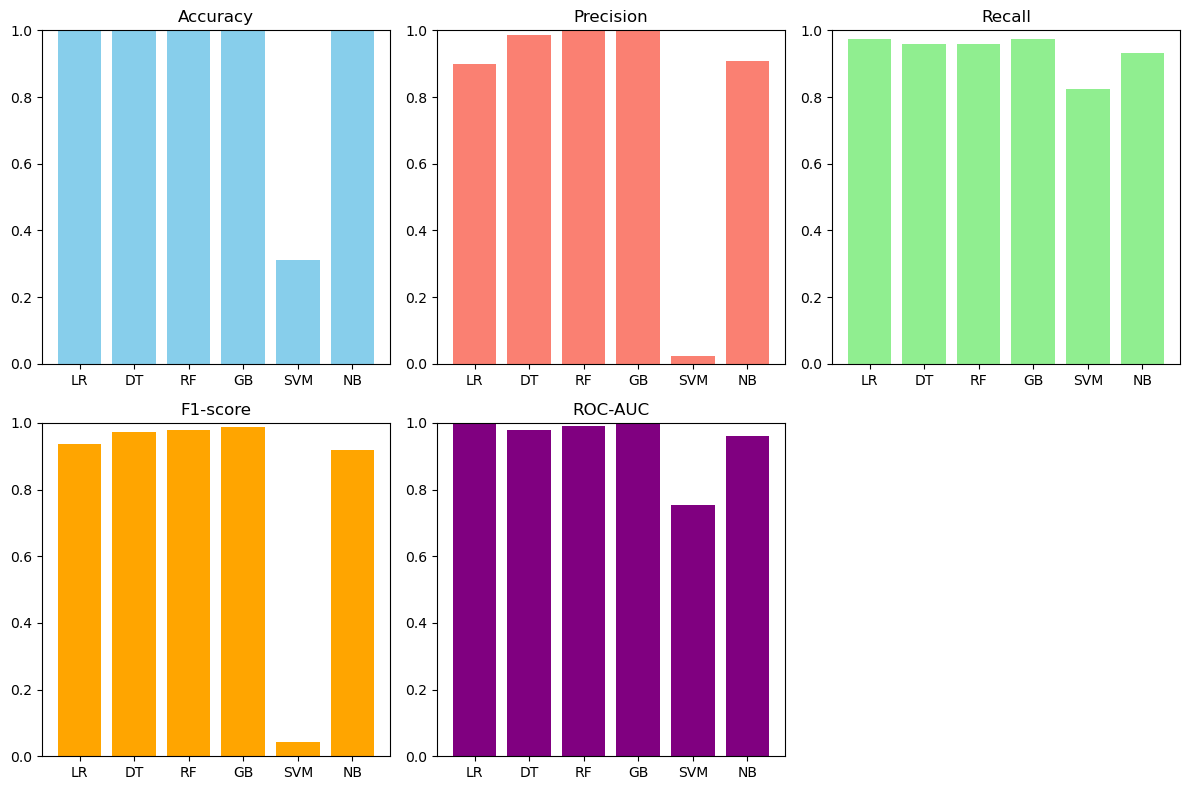

In [63]:
import matplotlib.pyplot as plt

# Example metrics for each model (replace with your actual outputs)
model_names = ['LR', 'DT', 'RF', 'GB', 'SVM', 'NB']

metrics_list = [
    lr_metrics,  # Output dict from run_classification for LR
    dt_metrics,  # Output dict for Decision Tree
    rf_metrics,  # Random Forest
    gb_metrics,  # Gradient Boosting
    svm_metrics, # SVM
    nb_metrics   # Naive Bayes
]

# Extract each metric for plotting
accuracy = [m['Accuracy'] for m in metrics_list]
precision = [m['Precision'] for m in metrics_list]
recall = [m['Recall'] for m in metrics_list]
f1 = [m['F1-score'] for m in metrics_list]
roc_auc = [m['ROC-AUC'] if m['ROC-AUC'] is not None else 0 for m in metrics_list]  # Replace None with 0 for plotting

# Plot
plt.figure(figsize=(12, 8))

plt.subplot(2, 3, 1)
plt.bar(model_names, accuracy, color='skyblue')
plt.title('Accuracy')
plt.ylim(0, 1)

plt.subplot(2, 3, 2)
plt.bar(model_names, precision, color='salmon')
plt.title('Precision')
plt.ylim(0, 1)

plt.subplot(2, 3, 3)
plt.bar(model_names, recall, color='lightgreen')
plt.title('Recall')
plt.ylim(0, 1)

plt.subplot(2, 3, 4)
plt.bar(model_names, f1, color='orange')
plt.title('F1-score')
plt.ylim(0, 1)

plt.subplot(2, 3, 5)
plt.bar(model_names, roc_auc, color='purple')
plt.title('ROC-AUC')
plt.ylim(0, 1)

plt.tight_layout()
plt.show()


### Optimizing the Model

In [52]:


def run_classification_with_tuning(df_clean,target_column=None, model_name=None, label_encode_cols=None, onehot_encode_cols=None, scale_cols=None, scaler=None, num_rows=None, model_params=None, n_splits=5, verbose=False):
    """
    Classification function with optional hyperparameter tuning and cross-validation.

    Returns model performance metrics and prints X, y, and their shapes safely.
    """

    # Copy DataFrame
    df_copy = df_clean.copy()

    # Sample rows if specified
    if num_rows is not None:
        df_copy = df_copy.sample(n=min(num_rows, len(df_copy)), random_state=42)

    # Separate X and y
    X = df_copy.drop(columns=[target_column, 'fraud_flag_mean', 'fraud_flag_max', 'fraud_flag_sum'], axis=1, errors='ignore')
    y = df_copy[target_column]

    # Train-test split first (to avoid data leakage)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Handle missing values on train and apply same imputer on test
    X_train, fitted_imputers = dynamic_imputer(X_train, fitted_imputers=None, fit=True)
    X_test, _ = dynamic_imputer(X_test, fitted_imputers=fitted_imputers, fit=False)

    
    # Label encoding
    
    if label_encode_cols:
        for col in label_encode_cols:
            label_encoder = LabelEncoder()
            X_train[col] = label_encoder.fit_transform(X_train[col])
            X_test[col] = label_encoder.transform(X_test[col])

    # One-hot encoding
    if onehot_encode_cols:
        X_train = pd.get_dummies(X_train, columns=onehot_encode_cols)
        X_test = pd.get_dummies(X_test, columns=onehot_encode_cols)
        # Align test to train columns
        X_test = X_test.reindex(columns=X_train.columns, fill_value=0)


    # Scaling
    if scale_cols and scaler:
        if scaler == 'standard':
            scaler_instance = StandardScaler()
        elif scaler == 'minmax':
            scaler_instance = MinMaxScaler()
        elif scaler == 'robust':
            scaler_instance = RobustScaler()
        else:
            raise ValueError("Invalid scaler. Choose 'standard', 'minmax', 'robust'.")
        X_train[scale_cols] = scaler_instance.fit_transform(X_train[scale_cols])
        X_test[scale_cols] = scaler_instance.transform(X_test[scale_cols])

    # Initialize model
    if model_name == 'LR':
        model_type = 'Logistic Regression'
        model = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
    elif model_name == 'DT':
        model_type = 'Decision Tree Classifier'
        model = DecisionTreeClassifier(random_state=42, class_weight='balanced')
    elif model_name == 'RF':
        model_type = 'Random Forest Classifier'
        model = RandomForestClassifier(random_state=42, class_weight='balanced')
    elif model_name == 'GB':
        model_type = 'Gradient Boosting Classifier'
        model = GradientBoostingClassifier(random_state=42)
    elif model_name == 'SVM':
        model_type = 'Support Vector Machine'
        model = SVC(probability=True, random_state=42, class_weight='balanced')
    elif model_name == 'NB':
        model_type = 'Naive Bayes Classifier'
        model = GaussianNB()
    else:
        raise ValueError("Invalid model_name. Choose 'LR', 'DT', 'RF', 'GB', 'SVM', 'NB'.")

    # Hyperparameter tuning
    if model_params:
        grid_search = GridSearchCV(
            estimator=model,
            param_grid=model_params,
            cv=KFold(n_splits=n_splits, shuffle=True, random_state=42),
            scoring='accuracy',
            n_jobs=-1
        )
        grid_search.fit(X_train, y_train)
        model = grid_search.best_estimator_
        print("Best Parameters:", grid_search.best_params_)

    # Fit model
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]) if hasattr(model, "predict_proba") else None

    # Print metrics
    print(f"\n{model_type} Accuracy:", accuracy)
    print(f"{model_type} Precision:", precision)
    print(f"{model_type} Recall:", recall)
    print(f"{model_type} F1-score:", f1)
    if roc_auc is not None:
        print(f"{model_type} ROC-AUC:", roc_auc)

    # Return metrics
    metrics = {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-score': f1,
        'ROC-AUC': roc_auc
    }

    return metrics


In [59]:
# Run Random Forest Regression model with hyperparameter tuning and 5-fold cross-validation

rf_params = {
    # Controls the maximum depth of each tree.
    # Shallower trees (e.g., 5) reduce overfitting, deeper trees (e.g., 15) capture more complexity.
    'max_depth': [5, 10, 15],

    # Minimum number of samples required to split an internal node.
    # Higher values (e.g., 50) make the tree more conservative and reduce overfitting.
    'min_samples_split': [10, 20, 50],

    # Minimum number of samples required to be at a leaf node.
    # Larger values (e.g., 10) prevent the model from learning from very small, noisy subsets.
    'min_samples_leaf': [5, 10]
}


rf_metrics_best = run_classification_with_tuning(customer_df, target_column=target_column_name, model_name='RF', label_encode_cols=label_encode_cols,
                                  onehot_encode_cols=onehot_encode_cols, scale_cols=scale_cols, scaler=scaler_name, model_params=rf_params, n_splits=5)


Best Parameters: {'max_depth': 5, 'min_samples_leaf': 5, 'min_samples_split': 10}

Random Forest Classifier Accuracy: 0.9992341077355119
Random Forest Classifier Precision: 1.0
Random Forest Classifier Recall: 0.9594594594594594
Random Forest Classifier F1-score: 0.9793103448275862
Random Forest Classifier ROC-AUC: 0.9978374158702028


In [53]:
lr_params = {'C': [0.1, 1, 10]}
lr_metrics_best = run_classification_with_tuning(customer_df, target_column=target_column_name, model_name='LR', label_encode_cols=label_encode_cols,
                                  onehot_encode_cols=onehot_encode_cols, scale_cols=scale_cols, scaler=scaler_name, model_params=lr_params, n_splits=5)

Best Parameters: {'C': 0.1}

Logistic Regression Accuracy: 0.9989788103140158
Logistic Regression Precision: 0.972972972972973
Logistic Regression Recall: 0.972972972972973
Logistic Regression F1-score: 0.972972972972973
Logistic Regression ROC-AUC: 0.9976404976404977


In [54]:
dt_params = {'max_depth': [5, 10, 15], 'min_samples_split': [10, 20]}

dt_metrics_best = run_classification_with_tuning(customer_df, target_column=target_column_name, model_name='DT', label_encode_cols=label_encode_cols,
                                  onehot_encode_cols=onehot_encode_cols, scale_cols=scale_cols, scaler=scaler_name, model_params=dt_params, n_splits=5)

Best Parameters: {'max_depth': 10, 'min_samples_split': 10}

Decision Tree Classifier Accuracy: 0.9979576206280316
Decision Tree Classifier Precision: 0.9342105263157895
Decision Tree Classifier Recall: 0.9594594594594594
Decision Tree Classifier F1-score: 0.9466666666666667
Decision Tree Classifier ROC-AUC: 0.9795785246604919


In [55]:
gb_params = {'n_estimators': [50, 100], 'learning_rate': [0.01, 0.1]}

gb_metrics_best = run_classification_with_tuning(customer_df, target_column=target_column_name, model_name='GB', label_encode_cols=label_encode_cols,
                                  onehot_encode_cols=onehot_encode_cols, scale_cols=scale_cols, scaler=scaler_name, model_params=gb_params, n_splits=5)

Best Parameters: {'learning_rate': 0.01, 'n_estimators': 100}

Gradient Boosting Classifier Accuracy: 0.9992341077355119
Gradient Boosting Classifier Precision: 1.0
Gradient Boosting Classifier Recall: 0.9594594594594594
Gradient Boosting Classifier F1-score: 0.9793103448275862
Gradient Boosting Classifier ROC-AUC: 0.9797297297297297


In [56]:
from sklearn.svm import LinearSVC


svm_params = {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']}

svm_metrics_best = run_classification_with_tuning(customer_df, target_column=target_column_name, model_name='SVM', label_encode_cols=label_encode_cols,
                                  onehot_encode_cols=onehot_encode_cols, scale_cols=scale_cols, scaler=scaler_name, model_params=svm_params, n_splits=3)

Best Parameters: {'C': 0.1, 'kernel': 'linear'}

Support Vector Machine Accuracy: 0.9994894051570079
Support Vector Machine Precision: 1.0
Support Vector Machine Recall: 0.972972972972973
Support Vector Machine F1-score: 0.9863013698630136
Support Vector Machine ROC-AUC: 0.9958119712218073


In [57]:
nb_params = {} 
nb_metrics_best = run_classification_with_tuning(customer_df, target_column=target_column_name, model_name='NB', label_encode_cols=label_encode_cols,
                                  onehot_encode_cols=onehot_encode_cols, scale_cols=scale_cols, scaler=scaler_name, model_params=nb_params, n_splits=5)


Naive Bayes Classifier Accuracy: 0.9982129180495277
Naive Bayes Classifier Precision: 0.971830985915493
Naive Bayes Classifier Recall: 0.9324324324324325
Naive Bayes Classifier F1-score: 0.9517241379310345
Naive Bayes Classifier ROC-AUC: 0.9597900007736073


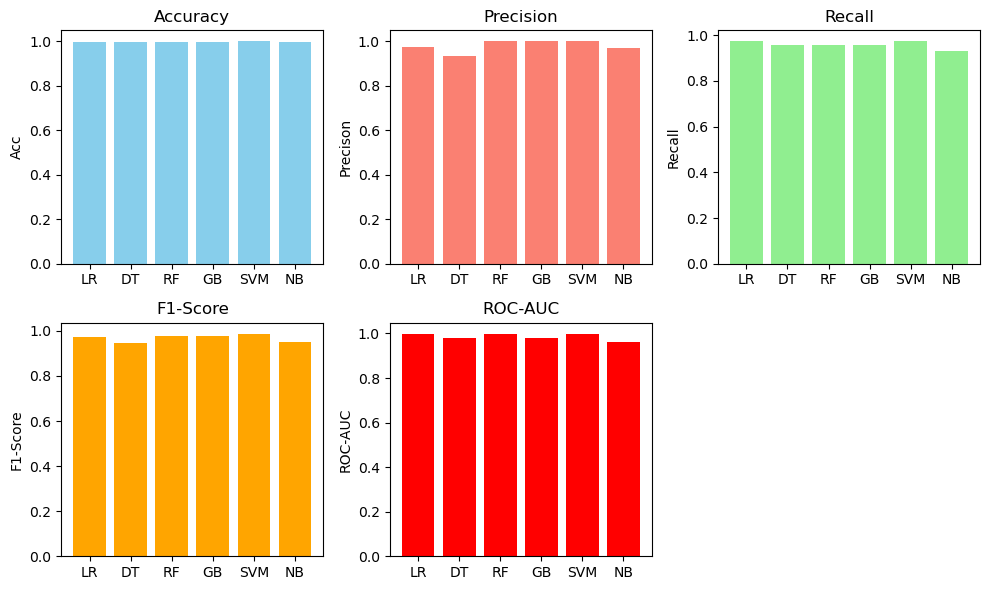

In [60]:
# Define the metrics for each model
models = ['LR', 'DT', 'RF', 'GB', 'SVM', 'NB']
accuracy = [lr_metrics_best['Accuracy'], dt_metrics_best['Accuracy'], rf_metrics_best['Accuracy'], gb_metrics_best['Accuracy'], svm_metrics_best['Accuracy'], nb_metrics_best['Accuracy']]
precision =  [lr_metrics_best['Precision'], dt_metrics_best['Precision'], rf_metrics_best['Precision'], gb_metrics_best['Precision'], svm_metrics_best['Precision'], nb_metrics_best['Precision']]
recall =  [lr_metrics_best['Recall'], dt_metrics_best['Recall'], rf_metrics_best['Recall'], gb_metrics_best['Recall'], svm_metrics_best['Recall'], nb_metrics_best['Recall']]
f1_scores =  [lr_metrics_best['F1-score'], dt_metrics_best['F1-score'], rf_metrics_best['F1-score'], gb_metrics_best['F1-score'], svm_metrics_best['F1-score'], nb_metrics_best['F1-score']]
roc_auc=  [lr_metrics_best['ROC-AUC'], dt_metrics_best['ROC-AUC'], rf_metrics_best['ROC-AUC'], gb_metrics_best['ROC-AUC'], svm_metrics_best['ROC-AUC'], nb_metrics_best['ROC-AUC']]

# Plotting the metrics
plt.figure(figsize=(10, 6))

plt.subplot(2, 3, 1)
plt.bar(models, accuracy, color='skyblue')
plt.title('Accuracy')
plt.ylabel('Acc')

plt.subplot(2, 3, 2)
plt.bar(models, precision, color='salmon')
plt.title('Precision')
plt.ylabel('Precison')

plt.subplot(2, 3, 3)
plt.bar(models, recall, color='lightgreen')
plt.title('Recall')
plt.ylabel('Recall')

plt.subplot(2, 3, 4)
plt.bar(models, f1_scores, color='orange')
plt.title('F1-Score')
plt.ylabel('F1-Score')

plt.subplot(2, 3, 5)
plt.bar(models, roc_auc, color='red')
plt.title('ROC-AUC')
plt.ylabel('ROC-AUC')


plt.tight_layout()
plt.show()

### Comparing the models before and after optimization

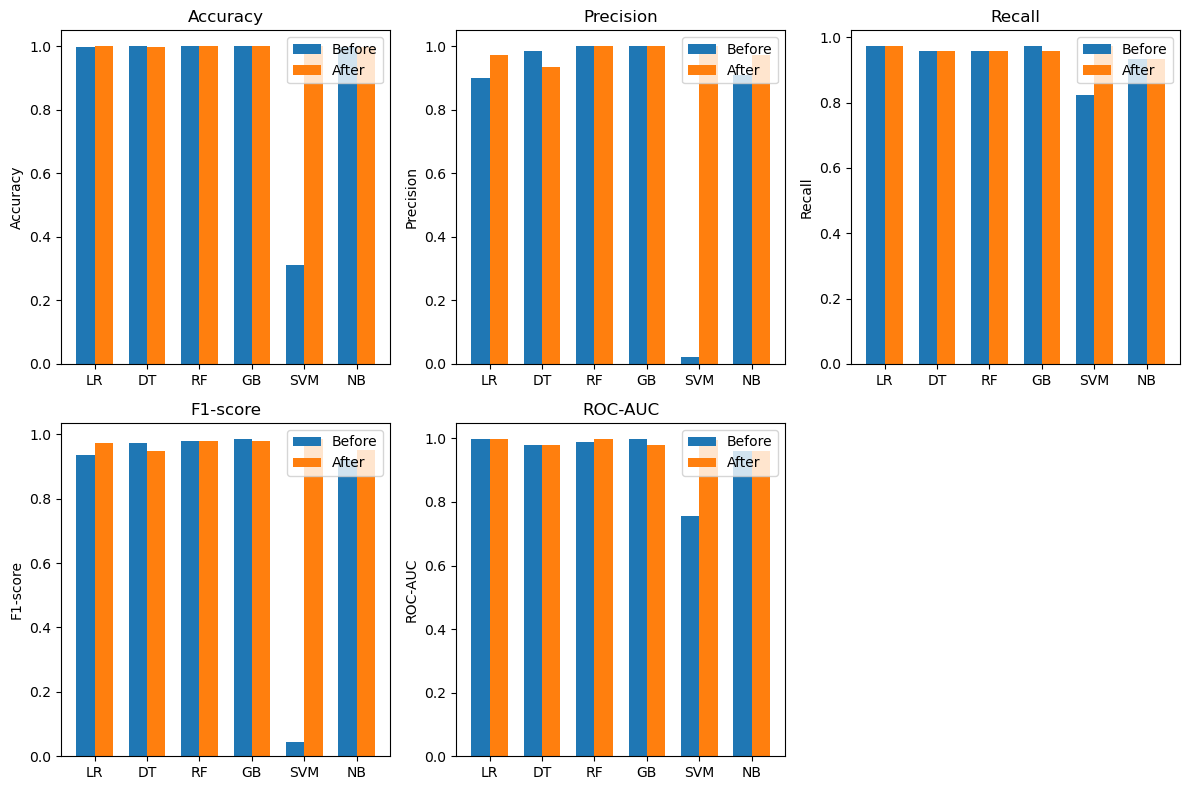

In [64]:
# Define the models and their corresponding metrics before optimization
models = ['LR', 'DT', 'RF', 'GB', 'SVM', 'NB']
metrics_before = {
   'Accuracy' : [lr_metrics['Accuracy'], dt_metrics['Accuracy'], rf_metrics['Accuracy'], gb_metrics['Accuracy'], svm_metrics['Accuracy'], nb_metrics['Accuracy']],
    'Precision' :  [lr_metrics['Precision'], dt_metrics['Precision'], rf_metrics['Precision'], gb_metrics['Precision'], svm_metrics['Precision'], nb_metrics['Precision']],
    'Recall' :  [lr_metrics['Recall'], dt_metrics['Recall'], rf_metrics['Recall'], gb_metrics['Recall'], svm_metrics['Recall'], nb_metrics['Recall']],
    'F1-score' :  [lr_metrics['F1-score'], dt_metrics['F1-score'], rf_metrics['F1-score'], gb_metrics['F1-score'], svm_metrics['F1-score'], nb_metrics['F1-score']],
    'ROC-AUC' : [lr_metrics['ROC-AUC'], dt_metrics['ROC-AUC'], rf_metrics['ROC-AUC'], gb_metrics['ROC-AUC'], svm_metrics['ROC-AUC'], nb_metrics['ROC-AUC']]
}
 

# Define the models and their corresponding metrics after optimization
metrics_after = {
    'Accuracy' : [lr_metrics_best['Accuracy'], dt_metrics_best['Accuracy'], rf_metrics_best['Accuracy'], gb_metrics_best['Accuracy'], svm_metrics_best['Accuracy'], nb_metrics_best['Accuracy']],
    'Precision' :  [lr_metrics_best['Precision'], dt_metrics_best['Precision'], rf_metrics_best['Precision'], gb_metrics_best['Precision'], svm_metrics_best['Precision'], nb_metrics_best['Precision']],
    'Recall' :  [lr_metrics_best['Recall'], dt_metrics_best['Recall'], rf_metrics_best['Recall'], gb_metrics_best['Recall'], svm_metrics_best['Recall'], nb_metrics_best['Recall']],
    'F1-score' :  [lr_metrics_best['F1-score'], dt_metrics_best['F1-score'], rf_metrics_best['F1-score'], gb_metrics_best['F1-score'], svm_metrics_best['F1-score'], nb_metrics_best['F1-score']],
    'ROC-AUC' :  [lr_metrics_best['ROC-AUC'], dt_metrics_best['ROC-AUC'], rf_metrics_best['ROC-AUC'], gb_metrics_best['ROC-AUC'], svm_metrics_best['ROC-AUC'], nb_metrics_best['ROC-AUC']]
}

# Plotting the metrics before and after optimization
fig, axs = plt.subplots(2, 3, figsize=(12, 8))

# Define the bar width
bar_width = 0.35
index = np.arange(len(models))

# Plot each metric separately
for i, metric in enumerate(metrics_before.keys()):
    axs[i//3, i%3].bar(index - bar_width/2, metrics_before[metric], bar_width, label='Before')
    axs[i//3, i%3].bar(index + bar_width/2, metrics_after[metric], bar_width, label='After')
    axs[i//3, i%3].set_title(metric)
    axs[i//3, i%3].set_ylabel(metric)
    axs[i//3, i%3].set_xticks(index)
    axs[i//3, i%3].set_xticklabels(models)
    axs[i//3, i%3].legend()


# turn off unused subplot
axs[1, 2].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
##### Among all the models, Random forest and Gradient Boosting has the best performance